# Customer Segmentation with Clustering
**Goal:** segment a set of wholesale customers into groups using k-means, decide how many
groups with the **elbow method** and the **silhouette score**, and explain what each segment is.



## Your dataset

Use the **Wholesale Customers** dataset: annual spending (monetary units) by 440 clients of a
wholesale distributor across product categories.

- Download: [UCI Wholesale Customers](https://archive.ics.uci.edu/dataset/292/wholesale+customers) (also searchable as "Wholesale customers" on Kaggle).
- Columns: `Channel`, `Region` (these are labels, not spending), then the six spend columns `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- Cluster on the **six spend columns**. `Channel` and `Region` are context only; do not cluster on them.

In [1]:
# Step 0: imports (given - just run this)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# ETSU_NAVY = "#00053E"
# ETSU_GOLD = "#FFC72C"
print("Ready.")

Ready.


## Step 1: Load the data

Using the full UCI Wholesale Customers file (440 clients), saved as `wholesale_customers.csv`.

In [2]:
# GIVEN: load the data
df = pd.read_csv("wholesale_customers.csv")
spend_cols = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## Step 2: Explore

Look at the data before clustering: size, column types, and the ranges of the spend columns
(the ranges tell you whether scaling is needed).

In [3]:
# Explore the data
print("Shape:", df.shape)
df.info()
print("\nMissing values:", df.isna().sum().sum())
df[spend_cols].describe().round(0)

Shape: (440, 8)
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values: 0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


**Observation:** 440 rows, 8 integer columns, no missing values. The spend columns are on very
different scales (Fresh averages about 12,000 and goes past 110,000, while Delicassen averages about 1,500)
and are heavily right-skewed, with a few very large customers. Without scaling, Fresh and Grocery
would dominate the distance calculation, so scaling is needed.

## Step 3: Select features and scale

k-means uses distance, and these spend columns are on very different scales, so scale them.

- Build X from the six spend columns.
- Scale with StandardScaler.

In [4]:
# Build X from the spend columns and scale it
X = df[spend_cols].values
Xs = StandardScaler().fit_transform(X)
print("Scaled shape:", Xs.shape)
print("Means (should be ~0):", Xs.mean(axis=0).round(2))
print("Std devs (should be 1):", Xs.std(axis=0).round(2))

Scaled shape: (440, 6)
Means (should be ~0): [-0.  0. -0.  0.  0. -0.]
Std devs (should be 1): [1. 1. 1. 1. 1. 1.]


## Step 4: Choose the number of clusters (elbow + silhouette)

Try a range of k (say 2 to 10). For each k, fit k-means and record two things:

- `kmeans.inertia_` for the **elbow** plot (tightness; look for where the curve bends),
- `silhouette_score(Xs, labels)` for the **silhouette** plot (separation; higher is better).

Plot both, then pick a k and justify it in a sentence.

 k  inertia  silhouette
 2   1956.0       0.547
 3   1608.0       0.548
 4   1318.0       0.348
 5   1059.0       0.369
 6    916.0       0.378
 7    825.0       0.334
 8    737.0       0.320
 9    661.0       0.309
10    606.0       0.311


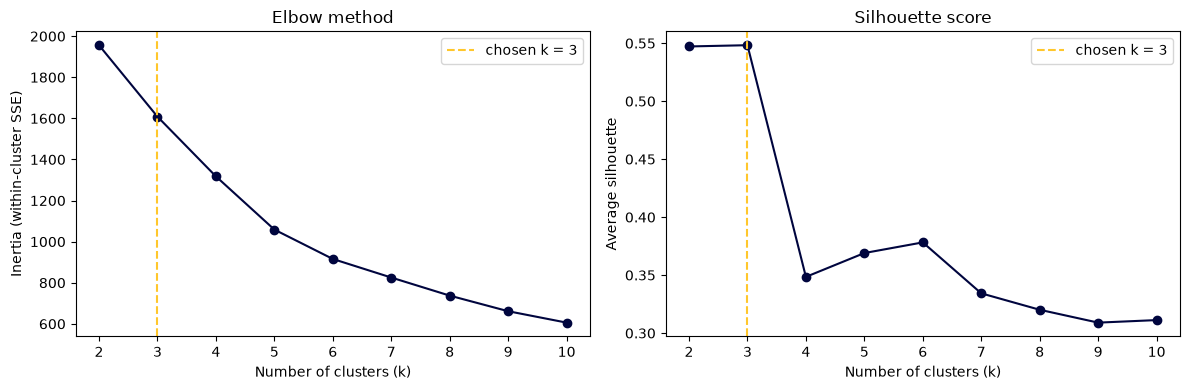

In [5]:
# Loop over k, collect inertia and silhouette, then plot both
ks = range(2, 11)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xs, km.labels_))

print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertias, 0), "silhouette": np.round(sils, 3)}).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, marker="o", color="#00053E")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[1].plot(list(ks), sils, marker="o", color="#00053E")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Average silhouette")
for ax in axes:
    ax.axvline(3, color="#FFC72C", linestyle="--", label="chosen k = 3")
    ax.legend()
plt.tight_layout()
plt.show()

**Your chosen k and why:**

I chose **k = 3**. It has the highest silhouette score of any k tried (0.548, slightly above k = 2 at 0.547),
and silhouette drops sharply to about 0.35 at k = 4. The elbow plot also bends around k = 3–4: after that, extra
clusters reduce inertia by smaller and smaller amounts.

## Step 5: Fit k-means with your chosen k

In [6]:
# Fit KMeans at k = 3 and attach the labels to df
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10).fit(Xs)
df["cluster"] = kmeans.labels_
df["cluster"].value_counts().sort_index()

cluster
0     45
1    393
2      2
Name: count, dtype: int64

## Step 6: Visualize the clusters with PCA

You have six features, so you cannot plot them directly. Reduce the scaled data to 2D with PCA
and color the points by cluster.

Variance explained by PC1 + PC2: 0.725


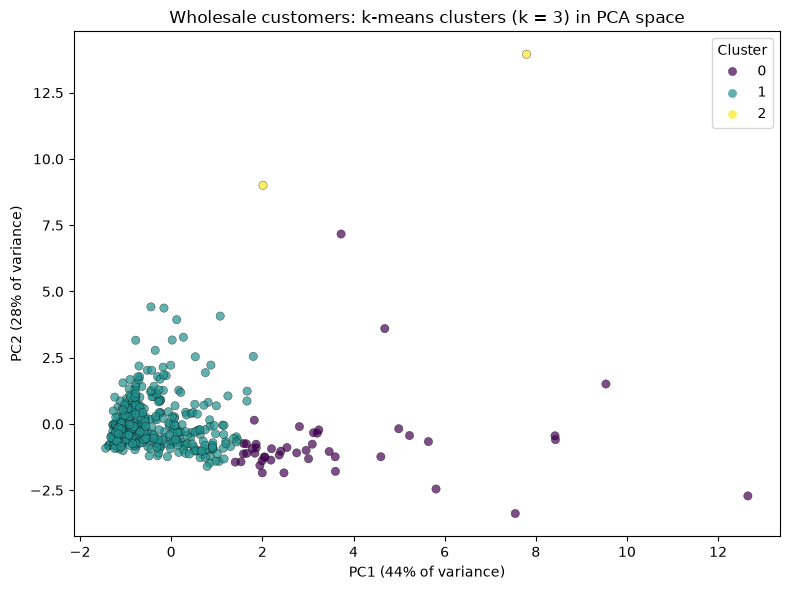

In [7]:
# Project Xs to 2D with PCA and scatter it, colored by cluster
pca = PCA(n_components=2)
pcs = pca.fit_transform(Xs)
print("Variance explained by PC1 + PC2:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
scatter = plt.scatter(pcs[:, 0], pcs[:, 1], c=df["cluster"], cmap="viridis", alpha=0.7, edgecolor="k", linewidth=0.3)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.title("Wholesale customers: k-means clusters (k = 3) in PCA space")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.tight_layout()
plt.show()

## Step 7: Profile and interpret the segments

Summarize each cluster by the average of each spend column (and how many customers are in it),
then describe each segment in plain words.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,n_customers
cluster,,,,,,,
0,10441.0,19386.0,28656.0,2190.0,13328.0,2374.0,45
1,12063.0,4115.0,5535.0,2941.0,1696.0,1299.0,393
2,34782.0,30367.0,16898.0,48702.0,756.0,26776.0,2


Channel,Horeca,Retail
cluster,,
0,1,44
1,295,98
2,2,0


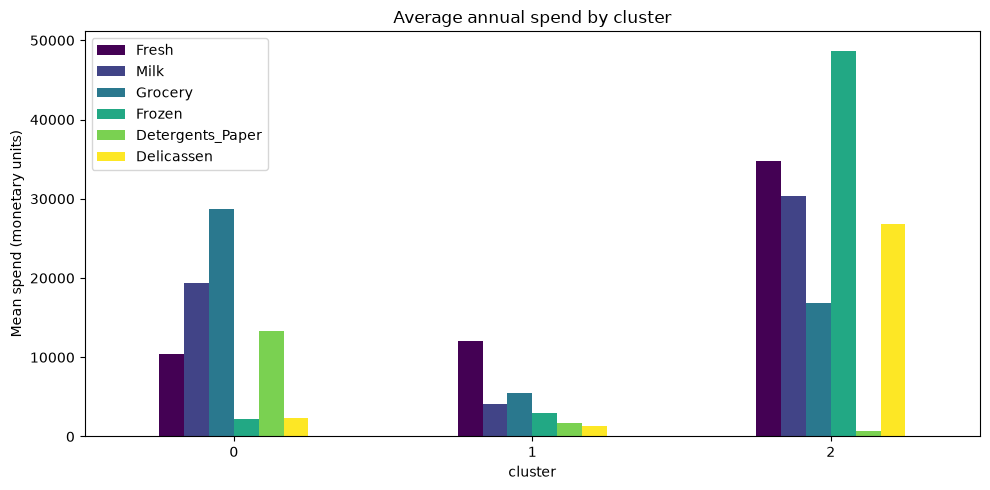

In [8]:
# Profile table of per-cluster averages, sizes, and how Channel lines up with each cluster
profile = df.groupby("cluster")[spend_cols].mean().round(0)
profile["n_customers"] = df["cluster"].value_counts().sort_index()
display(profile)

# Channel: 1 = Horeca (hotel/restaurant/cafe), 2 = Retail
display(pd.crosstab(df["cluster"], df["Channel"].map({1: "Horeca", 2: "Retail"})))

profile[spend_cols].plot(kind="bar", figsize=(10, 5), colormap="viridis")
plt.title("Average annual spend by cluster")
plt.ylabel("Mean spend (monetary units)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 8: Findings

1. **How many clusters did you choose, and why?**
   I chose **k = 3**. The silhouette score peaks at k = 3 (0.548) and drops to about 0.35 at k = 4. The elbow plot
   bends around k = 3–4, so adding more clusters after that gives smaller gains in tightness.

2. **Describe each segment:**
   - **Cluster 1: Fresh-leaning small/mid buyers (393 customers, ~89%).** Modest spend across the board, with
     Fresh (~12,000) as the largest category, and low Grocery, Milk, and Detergents_Paper. 295 of the 393 are
     Horeca (hotels, restaurants, cafés), so this is mostly the food-service crowd.
   - **Cluster 0: Grocery-heavy retailers (45 customers).** Very high Grocery (~28,700), Milk (~19,400), and
     Detergents_Paper (~13,300), with average Fresh and low Frozen. 44 of 45 are Retail channel, so these are
     supermarkets and grocery stores stocking packaged goods.
   - **Cluster 2: Very large all-category buyers (2 customers).** Huge spending in Fresh, Milk, Frozen (~48,700),
     and Delicassen (~26,800), but almost no Detergents_Paper. Both are Horeca, which suggests large
     catering or hospitality operations. These two are effectively outliers.

3. **One action per segment:**
   - **Cluster 1 (food service):** Offer reliable, frequent fresh-produce delivery and fresh/frozen bundles,
     because this large base cares most about perishables.
   - **Cluster 0 (grocery retailers):** Offer volume discounts and automatic restocking on grocery, milk, and
     detergent/paper lines, since that is where most of their spend goes.
   - **Cluster 2 (key accounts):** Give these few very large clients a dedicated account manager and custom
     contract pricing. Losing either one would cost a lot of revenue.

4. **One limitation:**
   The spend data is heavily skewed, and k-means is sensitive to outliers. Cluster 2 is only 2 customers and
   mostly captures extreme values. Next I would log-transform the spend columns (or remove the extreme outliers)
   before scaling, then re-run the elbow/silhouette check. That would show whether the large middle group
   splits into more useful segments (for example, separating fresh-heavy restaurants from smaller retailers).

## Submission checklist

- This notebook, renamed `Lastnames_Clustering.ipynb`, all cells run with output showing